[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pantrok/hidroxai-mx/blob/main/notebooks/tutoriales/02_cobertura_seleccion.ipynb)

# Tutorial 2 · Cobertura y selección de estaciones

**Objetivo.** calcular la cobertura de cada estación con la definición publicada, reproducir la selección de las estaciones hidrométricas y resumir la cobertura por unidad.

*Proyecto IND-2026-0335 · Instituto Politécnico Nacional (IPN) · Convocatoria PICDT2026. Datos: CONAGUA (Sistema de Información Hidrológica), INEGI y HydroSHEDS.*

In [1]:
# En Colab instala la biblioteca desde GitHub; fuera de Colab usa la que ya esté instalada.
# Va sin dependencias porque Colab ya trae pandas, pyarrow, matplotlib.
import importlib.util
import subprocess
import sys

if "google.colab" in sys.modules and importlib.util.find_spec("hidroxai_mx") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps",
                    "git+https://github.com/pantrok/hidroxai-mx@main"], check=True)

## 1. Criterios de selección

Se leen de la configuración con la que se construyó la versión (`conf/cuencas_piloto.yaml` dentro del ZIP).

In [2]:
import matplotlib.pyplot as plt

from hidroxai_mx import report
from hidroxai_mx.dataset import abrir_dataset, como_citar

ds = abrir_dataset()
crit = ds.configuracion()["criterios_seleccion_estaciones"]
periodo, umbral = crit["periodo"], crit["cobertura_minima"]
print(f"Periodo: {periodo['inicio']} a {periodo['fin']}")
print(f"Cobertura mínima: hidrométricas {umbral['hidrometricas']}, climatológicas {umbral['climatologicas']}")

Periodo: 2010-01-01 a 2025-12-31
Cobertura mínima: hidrométricas 0.6, climatológicas 0.8


## 2. Cobertura de las estaciones candidatas

La cobertura de una estación es el número de días con gasto **observado** (antes de imputar, es decir, sin `calidad = 1`) entre el 1 de enero de 2010 y el 31 de diciembre de 2025, dividido entre los días del periodo (5,844). El registro descargado termina el 3 de septiembre de 2025; los días posteriores cuentan en el denominador (ver `docs/nota_diseno_cobertura.md` del repositorio).

In [3]:
cand = ds.estaciones(conjunto="candidatas")
q = ds.series_hidrometricas(anios=range(2010, 2026),
                            columnas=["clave_estacion", "fecha", "gasto_medio_m3s", "calidad"])
observado = q[q["calidad"] != 1]
cob = report.coverage_table(observado, "gasto_medio_m3s", inicio=periodo["inicio"], fin=periodo["fin"])
cob = (cand[["clave", "nombre"]]
       .merge(cob.rename(columns={"clave_estacion": "clave"}), on="clave", how="left")
       .fillna({"cobertura": 0.0, "n_obs": 0}))
cob["seleccionada"] = cob["cobertura"] >= umbral["hidrometricas"]
print(f"Candidatas: {len(cand)}; con algún dato en el periodo: {(cob['n_obs'] > 0).sum()}; "
      f"con cobertura ≥ {umbral['hidrometricas']}: {cob['seleccionada'].sum()}")

Candidatas: 550; con algún dato en el periodo: 325; con cobertura ≥ 0.6: 101


El cálculo reproduce el catálogo publicado de estaciones seleccionadas:

In [4]:
sel = ds.estaciones()
mismas = set(cob.loc[cob["seleccionada"], "clave"]) == set(sel["clave"])
comp = sel[["clave", "cobertura"]].merge(cob[["clave", "cobertura"]], on="clave", suffixes=("_publicada", "_calculada"))
dif = (comp["cobertura_publicada"] - comp["cobertura_calculada"]).abs().max()
print(f"¿Las mismas {len(sel)} estaciones que el catálogo? {mismas}. Diferencia máxima de cobertura: {dif:.1e}")

¿Las mismas 101 estaciones que el catálogo? True. Diferencia máxima de cobertura: 1.1e-16


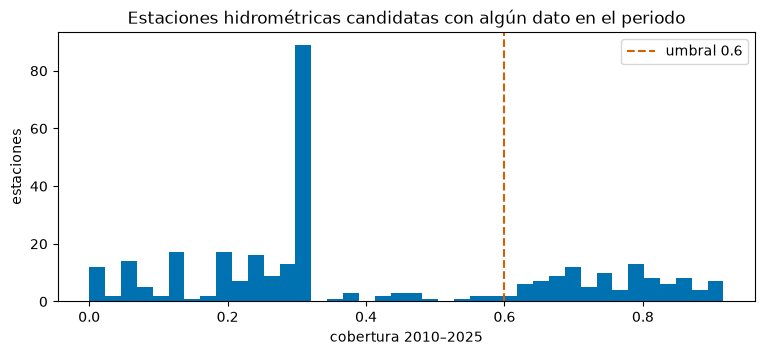

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(cob.loc[cob["n_obs"] > 0, "cobertura"], bins=40, color="#0072B2")
ax.axvline(umbral["hidrometricas"], color="#D55E00", ls="--", label=f"umbral {umbral['hidrometricas']}")
ax.set_xlabel("cobertura 2010–2025")
ax.set_ylabel("estaciones")
ax.set_title("Estaciones hidrométricas candidatas con algún dato en el periodo")
ax.legend()
plt.show()

## 3. Resumen por unidad

In [6]:
vinc = ds.vinculo_hidrorivers()
por_unidad = (sel.merge(vinc[["clave", "unidad_piloto"]], on="clave", how="left")
                 .fillna({"unidad_piloto": "fuera de unidad"})
                 .groupby("unidad_piloto")["cobertura"]
                 .agg(estaciones="size", mediana="median", minimo="min", maximo="max"))
por_unidad.round(3)

,estaciones,mediana,minimo,maximo
unidad_piloto,,,,
Alta del Balsas,12,0.672,0.635,0.760
Bajio,26,0.817,0.631,0.916
Cutzamala,1,0.661,0.661,0.661
Lerma Alto,8,0.704,0.639,0.863
Panuco,39,0.784,0.601,0.887
Santiago,9,0.705,0.617,0.755
fuera de unidad,6,0.740,0.690,0.770


La misma tabla, con los días faltantes, está publicada en `results/dib_revision/r2/cobertura_por_unidad.csv`. La fracción de días faltantes se da sobre el calendario completo y hasta el fin del registro:

In [7]:
pub = ds.leer_csv("results/dib_revision/r2/cobertura_por_unidad.csv").set_index("unidad")
pub[["estaciones_seleccionadas", "cobertura_mediana", "fraccion_dias_faltantes",
     "fin_registro", "fraccion_dias_faltantes_hasta_fin_registro"]].round(3)

,estaciones_seleccionadas,cobertura_mediana,fraccion_dias_faltantes,fin_registro,fraccion_dias_faltantes_hasta_fin_registro
unidad,,,,,
Alta del Balsas,12,0.672,0.166,2025-09-03,0.149
Bajio,26,0.817,0.142,2025-09-03,0.124
Cutzamala,1,0.661,0.291,2025-09-03,0.277
Lerma Alto,8,0.704,0.239,2025-09-03,0.224
Panuco,39,0.784,0.183,2025-09-03,0.166
Santiago,9,0.705,0.230,2025-09-03,0.214
fuera de unidad,6,0.740,0.166,2025-09-03,0.149
total,101,0.755,0.179,2025-09-03,0.162


## 4. Estaciones climatológicas

Su selección usa el umbral de 0.80. Aquí se resume la cobertura registrada en el catálogo publicado (no se recalcula: leer todas las series climatológicas implica unos 900 MB).

In [8]:
clima = ds.estaciones("climatologicas")
print(f"Climatológicas seleccionadas: {len(clima)}; cobertura mediana {clima['cobertura'].median():.3f} "
      f"(mínima {clima['cobertura'].min():.3f})")
report.station_inventory(clima.rename(columns={"clave": "clave_estacion"}), by="region_hidrologica")

Climatológicas seleccionadas: 415; cobertura mediana 0.950 (mínima 0.800)


,region_hidrologica,n_estaciones
2,26,154
0,12,149
1,18,112


## Cómo citar

Si usas estos datos, cita la versión del dataset que usaste. El texto sale de los metadatos del depósito en Zenodo.

In [9]:
print(como_citar())

Sánchez-Ruiz, D., Ramos Aguilar, E., Ramos-Aguilar, R., Reyes-Peña, C., Reyes-Cocoletzi, L., & García-Ramírez, J. (2026). Hidro-MX v2026.11: a reproducible hydroclimatic dataset for Mexican pilot basins (CONAGUA-SIH and INEGI) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.24119292
Todas las versiones (DOI de concepto): https://doi.org/10.5281/zenodo.21231600
Créditos: Instituto Politécnico Nacional (IPN) · Convocatoria PICDT2026 · proyecto IND-2026-0335. Datos: CONAGUA (Sistema de Información Hidrológica), INEGI y HydroSHEDS.
